# Big Data Analytics: Project 1
## What do viewers worry about in Samsung Galaxy Z Fold 8 videos?

**Business question:** A brand or retailer selling the Galaxy Z Fold 8 wants to know whether different types of review video attract different viewer concerns (price, durability, camera, battery, design, trust), and which concern it should address first.

**Data:** 2,000 public YouTube comments (400 per video) from 5 videos about the same product, collected with the YouTube Data API v3.

**Tools:** Python, Pandas, Matplotlib (the same workflow we would scale up later).

## 1. Data source, provenance and data dictionary

**Source:** YouTube Data API v3, `commentThreads.list`, collected on 24 Oct 2026 with `scrape_youtube.py`.
**What was collected:** top-level comments only (no replies), the 400 most recent per video (`order=time`).
**Privacy:** author names and channel IDs were not collected.
**Licence note:** the comments belong to their authors. They are used here for educational analysis, following the YouTube API Services Terms.

| Video | Channel | Type (category) |
|---|---|---|
| Z6z_feacXW8 | MKBHD | full_review |
| 8Hx2yvWSgs0 | MKBHD | first_impressions |
| HZOYCMkic0E | JerryRigEverything | durability_test |
| QHuIU2oE4Hg | Mrwhosetheboss | hands_on |
| Lgwa3Ze0tv4 | Unbox Therapy | product_showcase |

**Observational unit:** one row = one top-level YouTube comment.

| Column | Type | Meaning |
|---|---|---|
| video_id | text | YouTube video ID |
| video_title | text | Title of the video |
| category | categorical | Video type, assigned by us (see table above) |
| channel | categorical | Channel name, assigned by us |
| comment_id | text | Unique comment ID |
| text | text | The comment |
| likes | number | Likes on the comment when collected |
| reply_count | number | Number of replies to the comment |
| published_at | date/time | When the comment was posted (UTC) |
| text_length, word_count | number | Derived from `text` |
| mentions_price, mentions_durability, mentions_camera, mentions_battery, mentions_design, mentions_trust | True/False | Derived: does the comment contain words from that topic's keyword list |

## 2. Load the data and check its quality

In [14]:
import os
import time
import shutil
import tempfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)
pd.set_option("display.max_colwidth", 80)

df = pd.read_csv("data/youtube_comments.csv")
print("Rows, columns:", df.shape)
display(df.head())
df.info()

Rows, columns: (2000, 8)


,video_id,video_title,category,comment_id,text,likes,reply_count,published_at
0,Z6z_feacXW8,Galaxy Z Fold 8 Review: Honeymoon's Over,full_review,Ugy3SEcFOGgLs2jZKkp4AaABAg,cant wait to buy this in three years,0,0,2026-10-23T23:11:59Z
1,Z6z_feacXW8,Galaxy Z Fold 8 Review: Honeymoon's Over,full_review,Ugw09Ka9kb2ngJLD1jd4AaABAg,I want that wallpaper❤,1,0,2026-10-23T13:39:30Z
2,Z6z_feacXW8,Galaxy Z Fold 8 Review: Honeymoon's Over,full_review,Ugx2y_1ERxIhRGFKwy94AaABAg,I’m not Sold,0,0,2026-10-23T07:28:29Z
3,Z6z_feacXW8,Galaxy Z Fold 8 Review: Honeymoon's Over,full_review,UgyCv1l_PuLTox9jc7x4AaABAg,"1:11 I had the exact opposite experience with my s24+, I absolutely hated it...",0,0,2026-10-22T21:37:06Z
4,Z6z_feacXW8,Galaxy Z Fold 8 Review: Honeymoon's Over,full_review,Ugw_gdLr4UcIqLN2BSd4AaABAg,Not perfect - the business skills learn from Apple. Enjoy~,0,0,2026-10-22T18:16:47Z


<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   video_id      2000 non-null   str  
 1   video_title   2000 non-null   str  
 2   category      2000 non-null   str  
 3   comment_id    2000 non-null   str  
 4   text          1999 non-null   str  
 5   likes         2000 non-null   int64
 6   reply_count   2000 non-null   int64
 7   published_at  2000 non-null   str  
dtypes: int64(2), str(6)
memory usage: 125.1 KB


In [15]:
# Add the video type and channel (assigned by us)
CATEGORY_BY_VIDEO = {
    "Z6z_feacXW8": "full_review",
    "8Hx2yvWSgs0": "first_impressions",
    "HZOYCMkic0E": "durability_test",
    "QHuIU2oE4Hg": "hands_on",
    "Lgwa3Ze0tv4": "product_showcase",
}
CHANNEL_BY_VIDEO = {
    "Z6z_feacXW8": "MKBHD",
    "8Hx2yvWSgs0": "MKBHD",
    "HZOYCMkic0E": "JerryRigEverything",
    "QHuIU2oE4Hg": "Mrwhosetheboss",
    "Lgwa3Ze0tv4": "Unbox Therapy",
}
df["category"] = df["video_id"].map(CATEGORY_BY_VIDEO)
df["channel"] = df["video_id"].map(CHANNEL_BY_VIDEO)

print("Comments per video type:")
display(df["category"].value_counts(dropna=False))

Comments per video type:


category
full_review          400
first_impressions    400
durability_test      400
hands_on             400
product_showcase     400
Name: count, dtype: int64

In [16]:
# Quality checks: missing values, duplicates, column types
print("Missing values per column:")
display(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate comment IDs:", df["comment_id"].duplicated().sum())
display(df.describe(include="all").T)

Missing values per column:


video_id        0
video_title     0
category        0
comment_id      0
text            1
likes           0
reply_count     0
published_at    0
channel         0
dtype: int64

Duplicate rows: 0
Duplicate comment IDs: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
video_id,2000,5,Z6z_feacXW8,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
video_title,2000,5,Galaxy Z Fold 8 Review: Honeymoon's Over,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2000,5,full_review,400,NaN,NaN,NaN,NaN,NaN,NaN,NaN
comment_id,2000,2000,Ugy3SEcFOGgLs2jZKkp4AaABAg,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,1999,1986,👍,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,2000.0,NaN,NaN,NaN,2.6405,65.793949,0.0,0.0,0.0,0.0,2881.0
reply_count,2000.0,NaN,NaN,NaN,0.154,2.756099,0.0,0.0,0.0,0.0,120.0
published_at,2000,1999,2026-09-07T13:14:02Z,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
channel,2000,4,MKBHD,800,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Quality notes:** After cleaning, no column has missing values and every `comment_id` is unique. One comment (from the full_review video) was dropped during cleaning (it had no text, or was a duplicate), leaving 1,999 rows. `likes` and `reply_count` are very skewed: 83% of comments have 0 likes, the largest like count is 2,881 and the largest reply count is 120. Comment length ranges from 1 to 2,078 characters.

## 3. Clean the data and add useful columns

In [17]:
df["published_at"] = pd.to_datetime(df["published_at"], utc=True, errors="coerce")
df["text"] = df["text"].fillna("").astype(str).str.strip()

before = len(df)
# A comment with no text cannot be analysed; duplicates by comment_id are the same comment
df = df[df["text"] != ""].drop_duplicates(subset="comment_id").reset_index(drop=True)
print(f"Rows before: {before} | after cleaning: {len(df)}")

df["text_length"] = df["text"].str.len()
df["word_count"] = df["text"].str.split().str.len()

# Simple keyword lists for what viewers talk about (a rough first pass, not perfect)
TOPICS = {
    "price": r"price|expensive|cost|cheap|afford|worth|\$",
    "durability": r"crease|durab|scratch|hinge|break|broke|crack|dust|water|fragile",
    "camera": r"camera|photo|zoom|telephoto|lens",
    "battery": r"battery|charg",
    "design": r"design|thin|wide|size|screen|display|aspect|ratio|weight|heavy",
    "trust": r"sponsor|paid|\bads?\b|shill|affiliate|fake|bias",
}
for topic, pattern in TOPICS.items():
    df[f"mentions_{topic}"] = df["text"].str.contains(pattern, case=False, regex=True)

display(df[["category", "text", "likes", "reply_count"] + [f"mentions_{t}" for t in TOPICS]].head())

Rows before: 2000 | after cleaning: 1999


,category,text,likes,reply_count,mentions_price,mentions_durability,mentions_camera,mentions_battery,mentions_design,mentions_trust
0,full_review,cant wait to buy this in three years,0,0,False,False,False,False,False,False
1,full_review,I want that wallpaper❤,1,0,False,False,False,False,False,False
2,full_review,I’m not Sold,0,0,False,False,False,False,False,False
3,full_review,"1:11 I had the exact opposite experience with my s24+, I absolutely hated it...",0,0,False,False,False,False,True,False
4,full_review,Not perfect - the business skills learn from Apple. Enjoy~,0,0,False,False,False,False,False,False


## 4. Exploratory data analysis: statistics

In [18]:
# Statistic 1: typical engagement per video type (mean vs median)
summary = df.groupby("category").agg(
    comments=("comment_id", "count"),
    mean_likes=("likes", "mean"),
    median_likes=("likes", "median"),
    max_likes=("likes", "max"),
    mean_replies=("reply_count", "mean"),
    mean_words=("word_count", "mean"),
).round(2)
display(summary)
display(df[["likes", "reply_count", "text_length"]].describe().round(2))

,comments,mean_likes,median_likes,max_likes,mean_replies,mean_words
category,,,,,,
durability_test,400,0.82,0.0,159,0.05,15.31
first_impressions,400,0.46,0.0,97,0.07,21.66
full_review,399,7.69,0.0,2881,0.39,19.71
hands_on,400,1.92,0.0,211,0.15,24.40
product_showcase,400,2.33,0.0,459,0.11,24.17


,likes,reply_count,text_length
count,1999.00,1999.00,1999.00
mean,2.64,0.15,110.82
std,65.81,2.76,144.01
min,0.00,0.00,1.00
25%,0.00,0.00,36.00
50%,0.00,0.00,65.00
75%,0.00,0.00,131.00
max,2881.00,120.00,2078.00


In [19]:
# Statistic 2: are a few comments dominating the likes?
ranked = df["likes"].sort_values(ascending=False)
n_top = max(1, int(len(ranked) * 0.01))
share = ranked.head(n_top).sum() / max(ranked.sum(), 1)
print(f"Top 1% of comments ({n_top}) hold {share:.1%} of all likes")
print("Comments with 0 likes:", f"{(df['likes'] == 0).mean():.1%}")

# Statistic 3: how often each topic is mentioned, per video type (% of comments)
topic_cols = [c for c in df.columns if c.startswith("mentions_")]
topic_share = (df.groupby("category")[topic_cols].mean() * 100).round(1)
topic_share.columns = [c.replace("mentions_", "") for c in topic_share.columns]
display(topic_share)

# Relationship between numeric columns
display(df[["likes", "reply_count", "text_length"]].corr(method="spearman").round(2))

Top 1% of comments (19) hold 86.9% of all likes
Comments with 0 likes: 83.0%


,price,durability,camera,battery,design,trust
category,,,,,,
durability_test,5.2,17.0,2.0,0.2,19.5,0.8
first_impressions,13.0,6.2,4.8,2.5,28.5,0.2
full_review,9.3,3.8,6.3,2.3,24.3,0.3
hands_on,7.2,4.2,7.8,4.5,27.5,4.2
product_showcase,10.5,2.8,7.8,5.0,27.8,0.8


,likes,reply_count,text_length
likes,1.00,0.26,0.03
reply_count,0.26,1.00,0.06
text_length,0.03,0.06,1.00


## 5. Charts

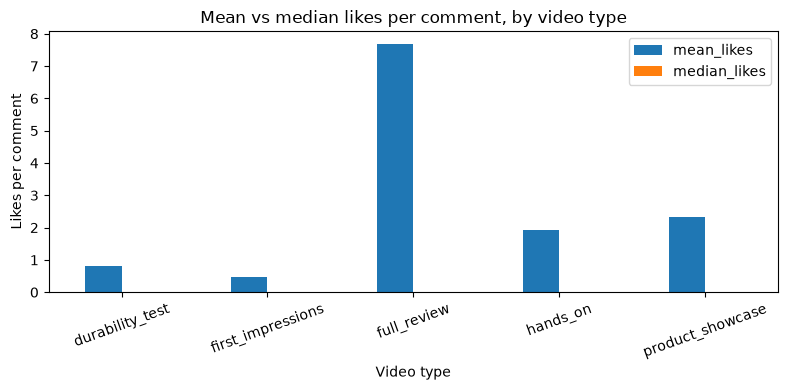

In [20]:
# Chart 1: mean vs median likes by video type
ax = summary[["mean_likes", "median_likes"]].plot(kind="bar", figsize=(8, 4))
ax.set_title("Mean vs median likes per comment, by video type")
ax.set_xlabel("Video type")
ax.set_ylabel("Likes per comment")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig("figures/chart1_likes_by_type.png", dpi=150)
plt.show()

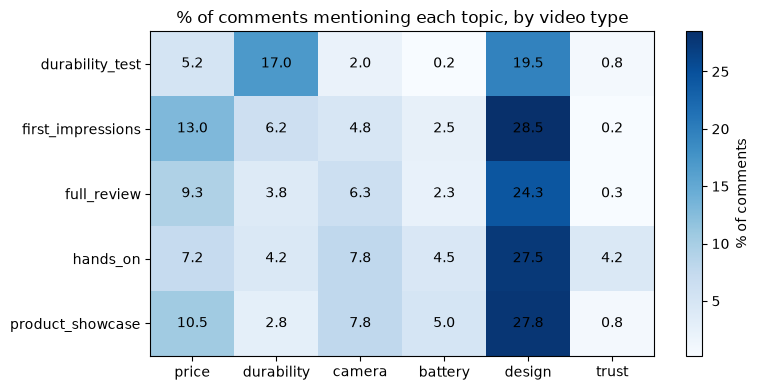

In [21]:
# Chart 2: what viewers talk about, by video type (% of comments mentioning each topic)
fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(topic_share.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(topic_share.columns)))
ax.set_xticklabels(topic_share.columns)
ax.set_yticks(range(len(topic_share.index)))
ax.set_yticklabels(topic_share.index)
for i in range(topic_share.shape[0]):
    for j in range(topic_share.shape[1]):
        ax.text(j, i, f"{topic_share.values[i, j]:.1f}", ha="center", va="center")
ax.set_title("% of comments mentioning each topic, by video type")
fig.colorbar(im, ax=ax, label="% of comments")
plt.tight_layout()
plt.savefig("figures/chart2_topics_by_type.png", dpi=150)
plt.show()

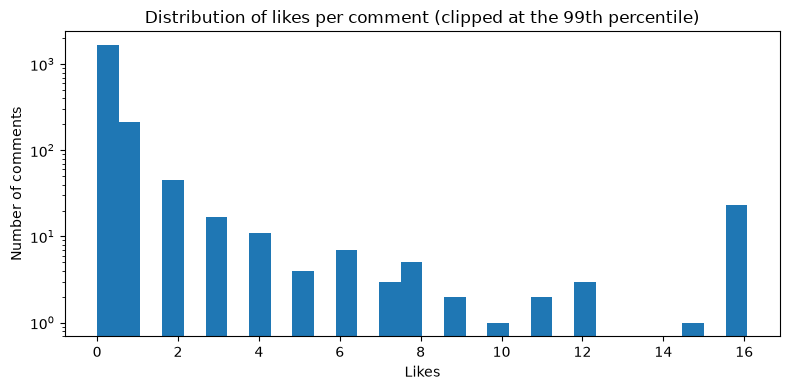

In [22]:
# Chart 3: distribution of likes (most comments get very few)
clip = df["likes"].quantile(0.99)
ax = df["likes"].clip(upper=clip).plot(kind="hist", bins=30, figsize=(8, 4))
ax.set_title("Distribution of likes per comment (clipped at the 99th percentile)")
ax.set_xlabel("Likes")
ax.set_ylabel("Number of comments")
ax.set_yscale("log")
plt.tight_layout()
plt.savefig("figures/chart3_likes_histogram.png", dpi=150)
plt.show()

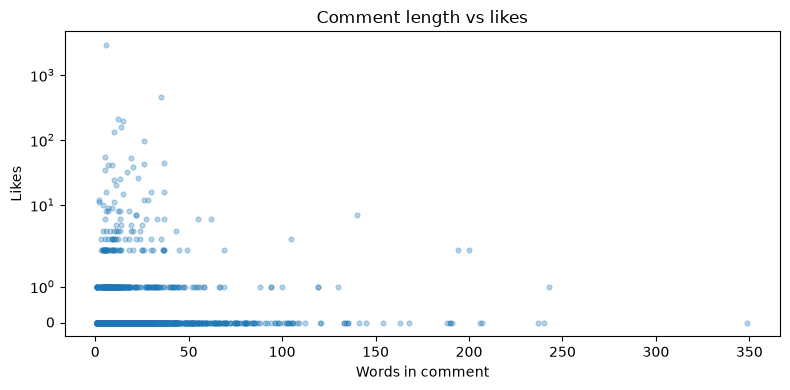

In [23]:
# Chart 4: do longer comments get more likes?
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(df["word_count"], df["likes"], alpha=0.3, s=12)
ax.set_title("Comment length vs likes")
ax.set_xlabel("Words in comment")
ax.set_ylabel("Likes")
ax.set_yscale("symlog")
plt.tight_layout()
plt.savefig("figures/chart4_length_vs_likes.png", dpi=150)
plt.show()

## 6. Observations and recommendation

**Observation 1: a few comments get almost all the likes.**
*Evidence:* 83% of comments have 0 likes (the median is 0 in every video type), and the top 1% of comments (19 comments) hold about 87% of all likes (Chart 3). The full_review video has the highest mean likes (7.69), but its median is still 0: one comment with 2,881 likes pulls the mean up. So mean likes per video type is misleading and does not show that one video type is more engaging.

**Observation 2: viewer concerns change with the video type.**
*Evidence:* (topic table and Chart 2) Price is mentioned in 13.0% of first_impressions comments and 10.5% of product_showcase comments, but only 5.2% of durability_test comments. Durability words appear in 17.0% of durability_test comments versus 2.8% to 6.2% in the other videos. Trust words (sponsored, paid, fake) are rare overall (1.3%) and highest in hands_on (4.2%).

**Marketing recommendation:** In this dataset, price comes up much more in launch-style videos (first impressions 13.0%, showcase 10.5%) than in the durability test (5.2%). A brand could test price and value messaging (for example, trade-in or bundle offers) in early launch content, and compare results using a consistent metric, such as the share of comments that mention price per 400 comments.

**Limitations:**
- Only the 400 most recent comments per video were collected, and the time window differs by video (durability_test comments go back to 14 Aug, while the latest product_showcase comment is from 16 Oct), so the videos are not compared over exactly the same period.
- Each video type has only one video, so differences may reflect that channel's audience, not just the video type.
- Topic detection uses simple keyword lists. It misses sarcasm and misspellings, and the "design" list is broad (it includes words like screen, wide and display), so treat it as a rough guide. Differences of a few percentage points between video types may be noise.
- Likes are heavily skewed, so statistics based on the mean should be read together with the median.

## 7. Scaling experiment: what changes when data grows?

We repeat the same small analysis on 1x, 10x, 100x and 1,000x copies of the data (2,000 rows up to 2,000,000 rows) and record file size, load time, analysis time and memory.

**Important:** repeated copies are a *scaling experiment only*. They are not new real-world evidence.

In [24]:
FACTORS = [1, 10, 100, 1000]   # 2,000 -> 2,000,000 rows. Remove 1000 if your laptop struggles.

base = df[["category", "text", "likes", "reply_count"]]
tmp_dir = tempfile.mkdtemp()     # temporary folder outside your project
results = []

for k in FACTORS:
    try:
        big = pd.concat([base] * k, ignore_index=True) if k > 1 else base.copy()
        path = os.path.join(tmp_dir, f"scaled_{k}x.csv")
        big.to_csv(path, index=False)
        size_mb = os.path.getsize(path) / 1e6
        rows = len(big)
        del big

        t0 = time.perf_counter()
        data = pd.read_csv(path)
        load_s = time.perf_counter() - t0

        t0 = time.perf_counter()
        data.groupby("category")["likes"].agg(["mean", "median"])
        data["text"].fillna("").str.contains("price|expensive|worth", case=False, regex=True).mean()
        analysis_s = time.perf_counter() - t0

        mem_mb = data.memory_usage(deep=True).sum() / 1e6
        del data
        results.append({"scale": f"{k}x", "rows": rows, "file_mb": round(size_mb, 1),
                        "load_s": round(load_s, 2), "analysis_s": round(analysis_s, 2),
                        "memory_mb": round(mem_mb, 1)})
        print(f"{k}x done: {rows:,} rows")
    except MemoryError:
        print(f"{k}x: ran out of memory. This is a real limit of this workflow on this laptop.")
        break

shutil.rmtree(tmp_dir, ignore_errors=True)
scaling = pd.DataFrame(results)
display(scaling)

1x done: 1,999 rows
10x done: 19,990 rows
100x done: 199,900 rows
1000x done: 1,999,000 rows


,scale,rows,file_mb,load_s,analysis_s,memory_mb
0,1x,1999,0.3,0.01,0.01,0.6
1,10x,19990,2.7,0.03,0.06,6.3
2,100x,199900,26.9,0.30,0.58,62.7
3,1000x,1999000,268.7,2.87,5.84,627.5


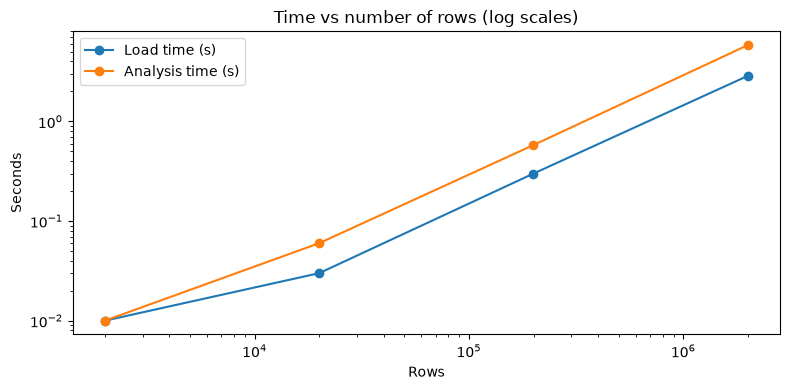

In [25]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(scaling["rows"], scaling["load_s"], marker="o", label="Load time (s)")
ax.plot(scaling["rows"], scaling["analysis_s"], marker="o", label="Analysis time (s)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_title("Time vs number of rows (log scales)")
ax.set_xlabel("Rows")
ax.set_ylabel("Seconds")
ax.legend()
plt.tight_layout()
plt.savefig("figures/chart5_scaling.png", dpi=150)
plt.show()

**Scaling notes:**
- Going from 2,000 rows to about 2 million rows (1,000x), file size grew from 0.3 MB to 268.7 MB, memory use from 0.6 MB to 627.5 MB, load time from 0.01 s to 3.13 s, and analysis time from 0.01 s to 6.53 s. Memory grew almost in a straight line with rows. From 100x to 1000x, rows grew 10 times while load and analysis time each grew about 11 times, so time also grew roughly in proportion. (The smallest runs are too fast to time precisely, so compare the larger ones.)
- The analysis step (the keyword search over every comment's text) was the slowest operation: at 1000x it took about twice as long as loading the file.
- Pandas on this laptop handled 2 million rows without any problem. There is no fixed row count where it fails.
- **Tool justification:** 627.5 MB of memory for 2 million rows means roughly 31 GB for 100 million rows if growth stays linear (an estimate, not measured), which is more than a typical laptop has. At that scale, or if the analysis had to be repeated every day on new data, a tool like Spark that spreads the work over several machines would be worth investigating. For this 2,000-row project, Pandas is the right tool.

## 8. Analytics techniques that could come next

- **Classification:** predict whether a comment will be high-engagement (or which topic it is about) after defining a label that is defensible. Avoid data leakage: do not build the label from `likes` and then present `likes` as a prediction input. Split training and test data.
- **Clustering:** group comments with similar features (length, topics, likes) to find types of viewers. Scale numeric features first.
- **Regression:** predict `likes` from comment features, if the data supports it.

**Exit question:** which of these would help the marketer, and what evidence would they need?

**Answer:** Classification would help most. A classifier that tags each comment as price, durability, camera and so on would turn thousands of comments into a dashboard of viewer concerns. The evidence needed is a hand-labelled sample of about 200 comments to measure how accurate it is, because our keyword rules miss sarcasm. Clustering could find types of viewers, but regression on likes would be weak because 83% of comments have 0 likes.

In [26]:
df.to_csv("data/youtube_comments_clean.csv", index=False)
print("Saved data/youtube_comments_clean.csv", df.shape)

Saved data/youtube_comments_clean.csv (1999, 17)
